# Hammett analysis

* Runs the electronic regression on the congeneric series that passed the feasibility screen in notebook 02, for both Nav1.1 and Nav1.6 endpoints.
* Seven compounds from scaffold 1, varying at the same R5 position - para position of the aromatic ring.

### Method

* Ordinary least squares of pChEMBL on σ_p, one fit per target using `scipy.stats.linregress`.
* σ_p is treated as error-free on the x-axis.
* pChEMBL carries the assay error and is the response.
* Because pChEMBL is already logarithmic quantity, the fitted slope is ρ and the intercept estimates the pChEMBL of the unsubstituted parent.
* Leave-one-out refits to check whether any single compound determines the result.

#### Inputs
* `hammett_candidates.csv` from `data/processed/`
* `constant_values.csv` from `data/raw/` — experimental σ values from Hansch, Leo and Taft, *Chem. Rev.* 1991, 91, 165–195

#### Outputs
* `hammett_nav.png` to `figures/`



In [ ]:
#imports

from pathlib import Path

import pandas as pd
import scipy
import matplotlib.pyplot as plt


In [2]:
#setting paths for the notebook

RAW = Path('../data/raw')
PROCESSED = Path('../data/processed')
FIGURES = Path('../figures')
FIGURES.mkdir(parents=True, exist_ok=True)

In [3]:
#dataset imports

constant_values = pd.read_csv(RAW / 'constant_values.csv')

hds = pd.read_csv(PROCESSED / 'hammett_candidates.csv')

In [4]:
hds.head(10)

,Unnamed: 0,Core,R1,R10,R11,R12,R13,R2,R3,R4,...,substituent_name,sigma_m,sigma_p,F,R,ref,pchembl_value_nav11,pchembl_value_nav16,canonical_smiles_nav16,scaffold_column
0,0,O=S(=O)(Nc1cscn1)c1c([*:1])c([*:2])c(N([C@@]2(...,[H][*:1],[H][*:10],C[*:11],[H][*:12],F[*:13],Cl[*:2],[H][*:3],[H][*:4],...,dimethylamino group,-0.16,-0.83,0.15,-0.98,"185,183",5.10,5.08,CN(C)c1ccc(CN2CC[C@H](N(C)c3cc(F)c(S(=O)(=O)Nc...,O=S(=O)(Nc1cscn1)c1ccc(NC2CCN(Cc3ccccc3)C2)cc1
1,1,O=S(=O)(Nc1cscn1)c1c([*:1])c([*:2])c(N([C@@]2(...,[H][*:1],[H][*:10],C[*:11],[H][*:12],F[*:13],Cl[*:2],[H][*:3],[H][*:4],...,hydrogen,0.00,0.00,0.03,0.00,no quotation,4.75,5.71,CN(c1cc(F)c(S(=O)(=O)Nc2cscn2)cc1Cl)[C@H]1CCN(...,O=S(=O)(Nc1cscn1)c1ccc(NC2CCN(Cc3ccccc3)C2)cc1
2,2,O=S(=O)(Nc1cscn1)c1c([*:1])c([*:2])c(N([C@@]2(...,[H][*:1],[H][*:10],C[*:11],[H][*:12],F[*:13],Cl[*:2],[H][*:3],[H][*:4],...,bromo substituent,0.39,0.23,0.45,-0.22,183,5.34,5.25,CN(c1cc(F)c(S(=O)(=O)Nc2cscn2)cc1Cl)[C@H]1CCN(...,O=S(=O)(Nc1cscn1)c1ccc(NC2CCN(Cc3ccccc3)C2)cc1
3,3,O=S(=O)(Nc1cscn1)c1c([*:1])c([*:2])c(N([C@@]2(...,[H][*:1],[H][*:10],C[*:11],[H][*:12],F[*:13],Cl[*:2],[H][*:3],[H][*:4],...,methyl group,-0.07,-0.17,0.01,-0.18,183,5.24,5.48,Cc1ccc(CN2CC[C@H](N(C)c3cc(F)c(S(=O)(=O)Nc4csc...,O=S(=O)(Nc1cscn1)c1ccc(NC2CCN(Cc3ccccc3)C2)cc1
4,4,O=S(=O)(Nc1cscn1)c1c([*:1])c([*:2])c(N([C@@]2(...,[H][*:1],[H][*:10],C[*:11],[H][*:12],F[*:13],Cl[*:2],[H][*:3],[H][*:4],...,propyl group,-0.06,-0.13,0.01,-0.14,"85,87",5.63,5.73,CCCc1ccc(CN2CC[C@H](N(C)c3cc(F)c(S(=O)(=O)Nc4c...,O=S(=O)(Nc1cscn1)c1ccc(NC2CCN(Cc3ccccc3)C2)cc1
5,5,O=S(=O)(Nc1cscn1)c1c([*:1])c([*:2])c(N([C@@]2(...,[H][*:1],[H][*:10],C[*:11],[H][*:12],F[*:13],Cl[*:2],[H][*:3],[H][*:4],...,chloro substituent,0.37,0.23,0.42,-0.19,183,5.49,5.38,CN(c1cc(F)c(S(=O)(=O)Nc2cscn2)cc1Cl)[C@H]1CCN(...,O=S(=O)(Nc1cscn1)c1ccc(NC2CCN(Cc3ccccc3)C2)cc1
6,7,O=S(=O)(Nc1cscn1)c1c([*:1])c([*:2])c(N([C@@]2(...,[H][*:1],[H][*:10],C[*:11],[H][*:12],F[*:13],Cl[*:2],[H][*:3],[H][*:4],...,fluoro substituent,0.34,0.06,0.45,-0.39,183,4.77,5.28,CN(c1cc(F)c(S(=O)(=O)Nc2cscn2)cc1Cl)[C@H]1CCN(...,O=S(=O)(Nc1cscn1)c1ccc(NC2CCN(Cc3ccccc3)C2)cc1


In [5]:
#listing dataset

list(hds.columns.values)


['Unnamed: 0',
 'Core',
 'R1',
 'R10',
 'R11',
 'R12',
 'R13',
 'R2',
 'R3',
 'R4',
 'R5',
 'R6',
 'R7',
 'R8',
 'R9',
 'molecule_chembl_id',
 'R5_stripped',
 'entry',
 'substituent_smiles',
 'formula',
 'substituent_name',
 'sigma_m',
 'sigma_p',
 'F',
 'R',
 'ref',
 'pchembl_value_nav11',
 'pchembl_value_nav16',
 'canonical_smiles_nav16',
 'scaffold_column']

In [6]:
#cleaning dataset

whds = hds.copy()

whds.drop(columns=['Unnamed: 0',
 'Core',
 'R1',
 'R10',
 'R11',
 'R12',
 'R13',
 'R2',
 'R3',
 'R4',
 'R5',
 'R6',
 'R7',
 'R8',
 'R9',
 'R5_stripped',
 'entry',
 'substituent_smiles',
 'sigma_m',
 'F',
 'R',
 'ref',
 'canonical_smiles_nav16',
 'scaffold_column'], inplace=True)

whds.head()

,molecule_chembl_id,formula,substituent_name,sigma_p,pchembl_value_nav11,pchembl_value_nav16
0,CHEMBL5840610,N(CH3)2,dimethylamino group,-0.83,5.10,5.08
1,CHEMBL5862561,H,hydrogen,0.00,4.75,5.71
2,CHEMBL5890000,Br,bromo substituent,0.23,5.34,5.25
3,CHEMBL5899667,CH3,methyl group,-0.17,5.24,5.48
4,CHEMBL5970405,CH2CH2CH3,propyl group,-0.13,5.63,5.73


In [7]:
#Rho calculation for Nav1.1

rho11 = scipy.stats.linregress(whds['sigma_p'],whds['pchembl_value_nav11'])

rho11

LinregressResult(slope=np.float64(0.1092728389264172), intercept=np.float64(5.198093775963587), rvalue=np.float64(0.11727508981111917), pvalue=np.float64(0.8022738981166061), stderr=np.float64(0.41382259439596725), intercept_stderr=np.float64(0.14370177390489028))

In [8]:
#Rho calculation for Nav1.6

rho16 = scipy.stats.linregress(whds['sigma_p'],whds['pchembl_value_nav16'])

rho16

LinregressResult(slope=np.float64(0.21794964418596235), intercept=np.float64(5.43470704042192), rvalue=np.float64(0.32793292722634804), pvalue=np.float64(0.47272914449132836), stderr=np.float64(0.28078927494820766), intercept_stderr=np.float64(0.09750534999767675))

Both values for slopes are close to 0.
Next step is seeing how much each substituent contributes to the slope.

In [9]:
#Rho impact for Nav1.6

slopes = [rho16[0]]
subs = ['none']
stderrs = [rho16[4]]
rvalues = [rho16[2]]

for i in range(0,7):
    subs.append(whds.loc[i, 'substituent_name'])
    newpd = whds.copy().drop(index=i)
    s = scipy.stats.linregress(newpd['sigma_p'],newpd['pchembl_value_nav16'])
    slopes.append(s[0])
    stderrs.append(s[4])
    rvalues.append(s[2])

rho_impact_16 = pd.DataFrame(data=[subs, slopes, stderrs, rvalues])
rho_impact_16 = rho_impact_16.transpose()
rho_impact_16.columns = ['substituent that is removed', 'slope', 'stderr', 'rvalue']
rho_impact_16['slope impact'] = rho_impact_16['slope'].apply(lambda x: x - rho16[0])

rho_impact_16

,substituent that is removed,slope,stderr,rvalue,slope impact
0,none,0.21795,0.280789,0.327933,0.000000
1,dimethylamino group,-0.805845,0.455925,-0.662209,-1.023795
2,hydrogen,0.182163,0.26662,0.323273,-0.035787
3,bromo substituent,0.346942,0.296113,0.505475,0.128992
4,methyl group,0.228116,0.311464,0.343869,0.010167
5,propyl group,0.238463,0.244927,0.437697,0.020514
6,chloro substituent,0.275534,0.331864,0.383407,0.057585
7,fluoro substituent,0.255567,0.30121,0.390544,0.037617


In [10]:
#Rho impact for Nav1.1

slopes = [rho11[0]]
subs = ['none']
stderrs = [rho11[4]]
rvalues = [rho11[2]]

for i in range(0,7):
    subs.append(whds.loc[i, 'substituent_name'])
    newpd = whds.copy().drop(index=i)
    s = scipy.stats.linregress(newpd['sigma_p'],newpd['pchembl_value_nav11'])
    slopes.append(s[0])
    stderrs.append(s[4])
    rvalues.append(s[2])

rho_impact_11 = pd.DataFrame(data=[subs, slopes, stderrs, rvalues])
rho_impact_11 = rho_impact_11.transpose()
rho_impact_11.columns = ['substituent that is removed', 'slope', 'stderr', 'rvalue']
rho_impact_11['slope impact'] = rho_impact_11['slope'].apply(lambda x: x - rho11[0])

rho_impact_11

,substituent that is removed,slope,stderr,rvalue,slope impact
0,none,0.109273,0.413823,0.117275,0.000000
1,dimethylamino group,0.0657,1.072448,0.030617,-0.043573
2,hydrogen,0.167523,0.375176,0.217894,0.058250
3,bromo substituent,0.045131,0.494387,0.045596,-0.064142
4,methyl group,0.11674,0.463546,0.124935,0.007468
5,propyl group,0.137551,0.375307,0.18025,0.028278
6,chloro substituent,-0.037262,0.463862,-0.040133,-0.146535
7,fluoro substituent,0.206722,0.383125,0.260471,0.097449


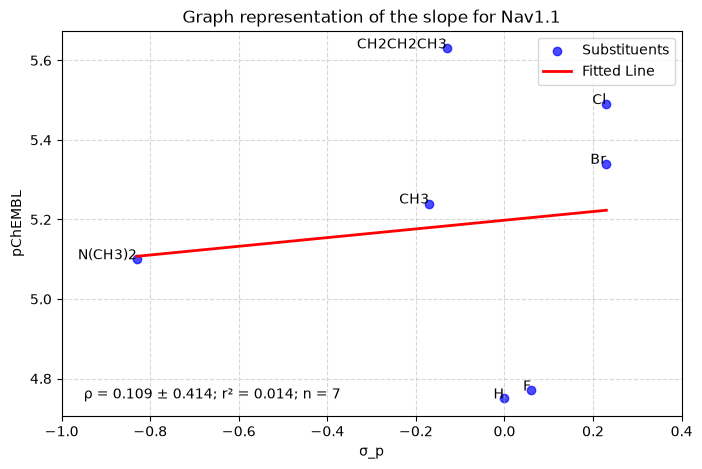

In [11]:
#graph representation of the slope for Nav1.1

whds.sort_values(by='sigma_p',inplace=True)

x=whds['sigma_p']
y=whds['pchembl_value_nav11']

plt.figure(figsize=(8, 5))
plt.scatter(x, y, color='blue', label='Substituents', alpha=0.7)
plt.plot(x, rho11.intercept + rho11.slope * x, color='red', linewidth=2, label='Fitted Line')

plt.title('Graph representation of the slope for Nav1.1')
plt.xlabel('σ_p')
plt.ylabel('pChEMBL')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
for i in range(len(whds)):
    plt.annotate(whds['formula'].iloc[i],(whds['sigma_p'].iloc[i],whds['pchembl_value_nav11'].iloc[i]),ha='right')

slope = round(rho11.slope,3)
stderr = round(rho11.stderr,3)
r2 = round(rho11.rvalue**2,3)

stringed = f'ρ = {slope} ± {stderr}; r² = {r2}; n = 7 '

plt.xlim(-1.0, 0.4)
plt.text(-0.95,4.75,s=stringed)

plt.show()

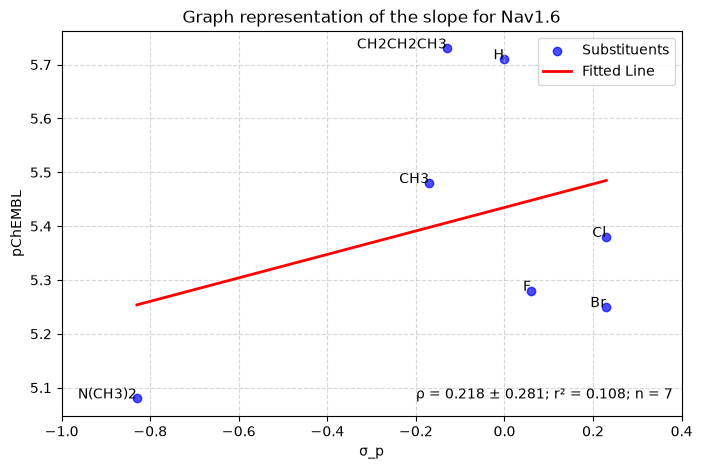

In [12]:
#graph representation of the slope for Nav1.6

whds.sort_values(by='sigma_p',inplace=True)

x=whds['sigma_p']
y=whds['pchembl_value_nav16']

plt.figure(figsize=(8, 5))
plt.scatter(x, y, color='blue', label='Substituents', alpha=0.7)
plt.plot(x, rho16.intercept + rho16.slope * x, color='red', linewidth=2, label='Fitted Line')

plt.title('Graph representation of the slope for Nav1.6')
plt.xlabel('σ_p')
plt.ylabel('pChEMBL')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
for i in range(len(whds)):
    plt.annotate(whds['formula'].iloc[i],(whds['sigma_p'].iloc[i],whds['pchembl_value_nav16'].iloc[i]),ha='right')

slope = round(rho16.slope,3)
stderr = round(rho16.stderr,3)
r2 = round(rho16.rvalue**2,3)

stringed = f'ρ = {slope} ± {stderr}; r² = {r2}; n = 7 '

plt.xlim(-1.0, 0.4)
plt.text(-0.2,5.08,s=stringed)

plt.show()

In [13]:
#Collecting values for paper substituents

target_subs_names = ['H','CH3','OCH3','Cl','Br','CN','NO2','F']
constant_values.head()
rug_values = constant_values[constant_values['formula'].isin(target_subs_names)]['sigma_p']
rug_values

3     0.00
4    -0.27
5     0.23
6     0.06
8     0.23
9    -0.17
17    0.66
29    0.78
Name: sigma_p, dtype: float64

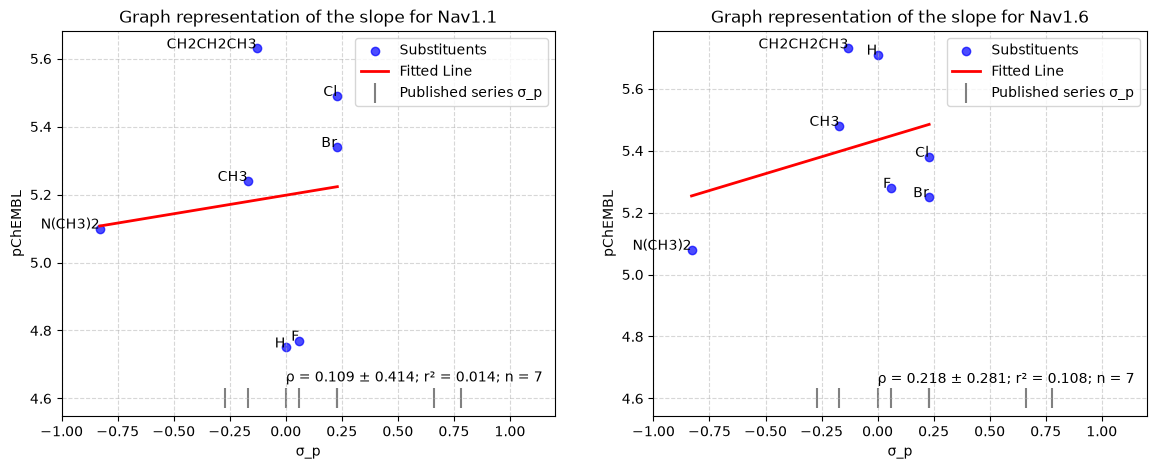

In [14]:
#Comparisson graph

whds.sort_values(by='sigma_p',inplace=True)

x=whds['sigma_p']
y=whds['pchembl_value_nav11']

y_pos = 4.6

fig, axes =plt.subplots(1, 2, figsize=(14, 5), sharex=True)

axes[0].scatter(x, y, color='blue', label='Substituents', alpha=0.7)
axes[0].plot(x, rho11.intercept + rho11.slope * x, color='red', linewidth=2, label='Fitted Line')
axes[0].scatter(rug_values, [y_pos]*len(rug_values), marker='|', s=200, color='grey', label='Published series σ_p')
axes[0].set_title('Graph representation of the slope for Nav1.1')
axes[0].set_xlabel('σ_p')
axes[0].set_ylabel('pChEMBL')
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.5)
for i in range(len(whds)):
    axes[0].annotate(whds['formula'].iloc[i],(whds['sigma_p'].iloc[i],whds['pchembl_value_nav11'].iloc[i]),ha='right')

slope11 = round(rho11.slope,3)
stderr11 = round(rho11.stderr,3)
r2_11 = round(rho11.rvalue**2,3)

stringed11 = f'ρ = {slope11} ± {stderr11}; r² = {r2_11}; n = 7 '

axes[0].set_xlim(-1.0, 1.2)
axes[0].text(0,4.65,s=stringed11)

y=whds['pchembl_value_nav16']

axes[1].scatter(x, y, color='blue', label='Substituents', alpha=0.7)
axes[1].plot(x, rho16.intercept + rho16.slope * x, color='red', linewidth=2, label='Fitted Line')
axes[1].scatter(rug_values, [y_pos]*len(rug_values), marker='|', s=200, color='grey', label='Published series σ_p')
axes[1].set_title('Graph representation of the slope for Nav1.6')
axes[1].set_xlabel('σ_p')
axes[1].set_ylabel('pChEMBL')
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.5)

for i in range(len(whds)):
    axes[1].annotate(whds['formula'].iloc[i],(whds['sigma_p'].iloc[i],whds['pchembl_value_nav16'].iloc[i]),ha='right')

slope16 = round(rho16.slope,3)
stderr16 = round(rho16.stderr,3)
r2_16 = round(rho16.rvalue**2,3)

stringed16 = f'ρ = {slope16} ± {stderr16}; r² = {r2_16}; n = 7 '

axes[1].text(0,4.65,s=stringed16)

axes[1].set_xlim(-1.0, 1.2)

plt.savefig(FIGURES / 'hammett_nav.png', dpi=150, bbox_inches='tight')
plt.show()

The graphs presented inside this notebook are not broken on two slopes due to the lack of range on the side of acceptor substituents ranging from 0.06 to 0.23 in σ_p values and donor substituents being dominated by a single substituent NMe₂. Rug values for the σ_p at the bottom of the graph shows how much the interval of the target compounds has better distribution of values. The point of slope break inside the paper graph occurs around ~ 0.3 point of σ_p.

### Hammett analysis results

For the Hammett analysis the chosen scaffold was: 

'O=S(=O)(Nc1cscn1)c1c([*:1])c([*:2])c(N([C@@]2([*:10])CC([*:9])N(C(c3c([*:4])cc([*:5])c([*:6])c3[*:7])[*:8])C2[*:3])[*:11])c([*:12])c1[*:13]' 

It has 7 distinct substituents: H, F, Cl, Br, CH₃, CH₂CH₂CH₃, NMe₂, in the position R5, with σ_p ranging from -0.83 to 0.23.

The excluded compound is R enantiomer of the H substituent. All the remaining compounds are S enantiomers, which kept stereochemistry consistent through the whole series. There is also difference in values for pIC50 between enantiomers, with R having 0.83 lower value than the S enantiomer for Nav1.6 receptor and 0.15 lower value for Nav1.1 receptor.


| Target | ρ | stderr | r² | p |
|---|---|---|---|---|
| Nav1.1 | 0.109 | 0.414 | 0.014 | 0.80 |
| Nav1.6 | 0.218 | 0.281 | 0.108 | 0.47 |

The slopes of the both endpoints are, unfortunately, indistinguishable from zero.

With the leave-one-out approach it was seen that there is no drastic impact on the value of the slope for any of the compounds, outside the NMe₂. The biggest shift is seen in removing the NMe₂ substituent whose removal changes the sign of the slope from positive to negative. In the literature the value of σ_p ranges from -0.21 all the way to -1.05 for NMe₂, making the impact of this substituent dependent on the source of the transcribed value.

The preregistered gate for candidates was σ_p range of at least 0.8. Without NMe₂ substituent the range collapses to -0.17 to 0.23, at which the series would not pass. The single substituent is the sole reason this series passed.

Result is that there was no observed correlation between the value of the pIC50 with the substituent.

Inside the original paper (DOI 10.2298/HEMIND181203007L), there was a closing statement that suggested that electron-withdrawing para substituents predict anticonvulsant potential. This was not a measured result, but rather a hypothesis on the chemical relationship between the substituent and the scaffold. The analysis inside this project does not disprove that claim, but rather it fails to confirm it.

It is worth noting that this is not the classical Hammett plot. There is no ionising reaction centre and the reference point is not defined by the reacting point on the para position, but rather the methylene linker. This is closer to the Hansch style single-term electronic regression.

